In [73]:
import os
import json
from typing import List, TypedDict

from langgraph.graph import StateGraph, END
from langchain_core.documents import Document
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_groq import ChatGroq

from langchain_community.vectorstores import FAISS
from langchain_community.retrievers import BM25Retriever
from langchain_classic.retrievers import EnsembleRetriever

In [113]:
from dotenv import load_dotenv

load_dotenv()

if not os.getenv("GROQ_API_KEY"):
    raise ValueError("GROQ_API_KEY is missing from .env")

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0.2,
    max_tokens=4096,
    reasoning_effort="low"
)

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

print("LLM and embedding model initialized.")



Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4119.12it/s]


LLM and embedding model initialized.


In [75]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.6', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000022984FB3890>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000022A0C7582D0>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [76]:
# JSON_PATH = "flipkart_review_documents.json"

# if not os.path.exists(JSON_PATH):
#     raise FileNotFoundError(
#         f"JSON file not found: {JSON_PATH}"
#     )

# with open(JSON_PATH, "r", encoding="utf-8") as f:
#     data = json.load(f)

# # Support either a list of documents or a wrapped JSON object.
# if isinstance(data, dict):
#     data = data.get("documents", data.get("chunks", []))

# if not isinstance(data, list) or not data:
#     raise ValueError("JSON must contain a non-empty list of documents.")

# documents = []

# for i, item in enumerate(data):
#     if not isinstance(item, dict):
#         continue

#     content = item.get("page_content") or item.get("text")
#     if not content:
#         continue

#     metadata = item.get("metadata", {})
#     if not isinstance(metadata, dict):
#         metadata = {}

#     documents.append(
#         Document(
#             page_content=str(content),
#             metadata=metadata
#         )
#     )

# if not documents:
#     raise ValueError(
#         "No usable documents found. Check the JSON structure."
#     )

# print(f"Loaded {len(documents)} documents.")
# print("\nExample document:")
# print(documents[0].page_content)
# print("\nMetadata:")
# print(documents[0].metadata)

import json
from langchain_core.documents import Document

JSON_PATH = "flipkart_review_documents.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    documents_data = json.load(f)

review_docs = [
    Document(
        page_content=item["page_content"],
        metadata=item["metadata"]
    )
    for item in documents_data
]

print("Total documents:", len(review_docs))

Total documents: 35853


In [77]:
# A. Semantic vector store using FAISS
vector_store = FAISS.from_documents(
    documents=review_docs,
    embedding=embeddings
)
bm25_retriever = BM25Retriever.from_documents(documents)
# bm25_retriever.k = 30

bm25_retriever.k = 30

faiss_retriever = vector_store.as_retriever(
    search_kwargs={"k": 30}
)

hybrid_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, faiss_retriever],
    weights=[0.5, 0.5]
)



print("FAISS vector store created.")
print("BM25 keyword retriever created.")
print("Hybrid retriever is ready.")

FAISS vector store created.
BM25 keyword retriever created.
Hybrid retriever is ready.


In [78]:
class AgentState(TypedDict):
    question: str
    context: List[Document]
    answer: str
    needs_retrieval: bool
    

In [79]:
def retrieve_documents(state: AgentState) -> AgentState:
    question = state["question"]

    # BM25 retrieves the top 25 relevant documents
    docs = hybrid_retriever.invoke(question)[:25]

    return {**state, "context": docs}


In [80]:
# test_query = "Which Poco phones have 8 GB RAM?"

# results = retriever.invoke(test_query)

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)
#     print("Metadata:", doc.metadata)

In [81]:
# import re

# def get_field(doc, field):
#     # First try the document text
#     pattern = rf"{field}\s*:\s*([^,\n.]+)"
#     match = re.search(pattern, doc.page_content, re.IGNORECASE)

#     if match:
#         return match.group(1).strip()

#     # Fall back to metadata
#     for key, value in doc.metadata.items():
#         if key.lower() == field.lower() and value is not None:
#             return str(value).strip()

#     return ""


# def exact_mobile_search(query):
#     q = query.lower()

#     # Detect the requested brand
#     brands = ["poco", "realme", "samsung", "apple",
#               "redmi", "xiaomi", "vivo", "oppo"]

#     required_brand = next((b for b in brands if b in q), None)

#     # Detect RAM requirement, e.g. "8 GB RAM"
#     ram_match = re.search(r"(\d+)\s*gb\s*ram", q)
#     required_ram = int(ram_match.group(1)) if ram_match else None

#     results = []

#     # Search ALL documents, not just the top retrieved candidates
#     for doc in documents:
#         brand = get_field(doc, "Brand").lower()
#         ram_text = get_field(doc, "RAM")

#         # Accept only an exact brand match
#         if required_brand and brand != required_brand:
#             continue

#         # Match RAM value
#         if required_ram is not None:
#             ram_match_doc = re.search(r"\d+", ram_text)
#             if not ram_match_doc:
#                 continue

#             if int(ram_match_doc.group()) != required_ram:
#                 continue

#         results.append(doc)

#     return results


# results = exact_mobile_search("Which Poco phones have 8 GB RAM?")

# print(f"Matching documents found: {len(results)}")

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)
#     print("Metadata:", doc.metadata)

In [82]:
# def smart_mobile_search(query: str, k: int = 5):
#     q = query.lower()

#     # Detect structured constraints
#     brands = [
#         "poco", "realme", "samsung", "apple",
#         "redmi", "xiaomi", "vivo", "oppo"
#     ]
#     required_brand = next(
#         (brand for brand in brands if brand in q), None
#     )

#     ram_match = re.search(r"(\d+)\s*gb\s*ram", q)
#     required_ram = int(ram_match.group(1)) if ram_match else None

#     # Use exact filtering when brand or RAM is specified
#     if required_brand or required_ram is not None:
#         matches = exact_mobile_search(query)

#         if matches:
#             return matches[:k]

#     # Otherwise, use the hybrid retriever
#     return retriever.invoke(query)[:k]


In [83]:
from sentence_transformers import CrossEncoder

# Load a reranking model
reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

print("Reranker loaded successfully!")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 3448.29it/s]


Reranker loaded successfully!


In [84]:
def rerank_documents(question, documents, top_k=10):
    if not documents:
        return []

    pairs = [
        (question, doc.page_content)
        for doc in documents
    ]

    scores = reranker.predict(pairs)

    ranked_docs = sorted(
        zip(documents, scores),
        key=lambda item: float(item[1]),
        reverse=True
    )

    return [
        doc for doc, score in ranked_docs[:top_k]
    ]

In [85]:
question = "What do customers say about the cooling performance?"

retrieved_docs = hybrid_retriever.invoke(question)

reranked_docs = rerank_documents(
    question,
    retrieved_docs,
    top_k=5
)

for i, doc in enumerate(reranked_docs, start=1):
    print(f"\n--- Review {i} ---")
    print(doc.page_content)



--- Review 1 ---
Product: MAHARAJA WHITELINE 65 L Desert Air Cooler??????(White, Grey, Rambo Grey / AC-303)
Rating: 5.0
Review: cooler performance is excellent cooling is at its best when its placed outside the windowi dont know about service but have to see in futurebest buy but old date product is shippedthat should nt be expected from flipkarti got little dissatisfaction still its ok because its working goodfinally the product is good

--- Review 2 ---
Product: MAHARAJA WHITELINE 65 L Desert Air Cooler??????(White, Grey, Rambo Grey / AC-303)
Rating: 1.0
Review: the product doesnt cool as rated by other customers the cooling is very slow very wrost product i recommend to not buy this item wastage of money

--- Review 3 ---
Product: MAHARAJA WHITELINE 65 L Desert Air Cooler??????(White, Grey, Rambo Grey / AC-303)
Rating: 4.0
Review: performance wise is ok cooling is good but the cooler plastic body quality is not very good

--- Review 4 ---
Product: MAHARAJA WHITELINE 65 L Desert Air

In [86]:
for doc, score in sorted(
    zip(retrieved_docs, reranker.predict([
        (question, doc.page_content)
        for doc in retrieved_docs
    ])),
    key=lambda x: float(x[1]),
    reverse=True
)[:5]:
    print(f"Score: {float(score):.4f}")
    print(doc.page_content)
    print("-" * 60)

Score: -0.0225
Product: MAHARAJA WHITELINE 65 L Desert Air Cooler??????(White, Grey, Rambo Grey / AC-303)
Rating: 5.0
Review: cooler performance is excellent cooling is at its best when its placed outside the windowi dont know about service but have to see in futurebest buy but old date product is shippedthat should nt be expected from flipkarti got little dissatisfaction still its ok because its working goodfinally the product is good
------------------------------------------------------------
Score: -3.7014
Product: MAHARAJA WHITELINE 65 L Desert Air Cooler??????(White, Grey, Rambo Grey / AC-303)
Rating: 1.0
Review: the product doesnt cool as rated by other customers the cooling is very slow very wrost product i recommend to not buy this item wastage of money
------------------------------------------------------------
Score: -4.1896
Product: MAHARAJA WHITELINE 65 L Desert Air Cooler??????(White, Grey, Rambo Grey / AC-303)
Rating: 4.0
Review: performance wise is ok cooling is good b

In [87]:
print(reranker)
print(reranker.model_card_data)

CrossEncoder(
  (0): Transformer({'transformer_task': 'sequence-classification', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'logits'}}, 'module_output_name': 'scores', 'architecture': 'BertForSequenceClassification'})
)
tags:
- sentence-transformers
- cross-encoder
- reranker
base_model: cross-encoder/ms-marco-MiniLM-L6-v2
pipeline_tag: text-ranking
library_name: sentence-transformers


In [88]:
# question = "What are the common complaints about this air cooler?"

# retrieved_docs = hybrid_retriever.invoke(question)

# reranked_docs = rerank_documents(
#     question,
#     retrieved_docs,
#     top_k=5
# )

# context = "\n\n".join(
#     doc.page_content for doc in reranked_docs
# )

# print(context)

question = "What are the common complaints about Crompton 75 L Desert Air Cooler?"

retrieved_docs = hybrid_retriever.invoke(question)

reranked_docs = rerank_documents(
    question,
    retrieved_docs,
    top_k=5
)

for i, doc in enumerate(reranked_docs, start=1):
    print(f"\nRank: {i}")
    print("Product:", doc.metadata.get("product_name"))
    print("Rating:", doc.metadata.get("rating"))
    print("Review:", doc.page_content)


Rank: 1
Product: Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)
Rating: 5.0
Review: Product: Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)
Rating: 5.0
Review: love this product no any complaint

Rank: 2
Product: Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)
Rating: 1.0
Review: Product: Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)
Rating: 1.0
Review: worst experienceiam writing this review after using this cooler for one week iam not at all satisfied with the product no cooling at all its just like a normal fan no support from crompton people and seller rejected my return request without asking my feedback totally disappointed with this service

Rank: 3
Product: Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)
Rating: 2.0
Review: Product: Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)
Rating: 2.0
Review: not a good oneits not throwing any cool air and a lot of noisy

Rank: 4
Product:

In [89]:
# results = bm25_retriever.invoke(
#     "Which Poco phones have 8 GB RAM?"
# )[:25]

# print(f"Matching documents retrieved: {len(results)}")

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)

# bm25_retriever.k = 25

# query = "Poco phones with 8 GB RAM"

# results = bm25_retriever.invoke(query)

# print("Documents retrieved:", len(results))

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)


# query = "Which Poco phones have 8 GB RAM?"
# results = hybrid_retriever.invoke(query)

# print("Retrieved documents:", len(results))

# for i, doc in enumerate(results, 1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)


# def filter_by_battery_capacity(documents, target_capacity):
#     return [
#         doc for doc in documents
#         if doc.metadata.get("battery_capacity") == target_capacity
#     ]
# query = "Which phones have a 6000 mAh battery?"

# candidates = hybrid_retriever.invoke(query)

# ranked_results = rerank_documents(
#     query,
#     candidates,
#     top_k=30
# )

# matching_results = filter_by_battery_capacity(
#     ranked_results,
#     6000
# )

# print("Exact battery matches:", len(matching_results))

# for i, doc in enumerate(matching_results, 1):
#     print(
#         f"{i}. {doc.metadata.get('brand')} "
#         f"{doc.metadata.get('model')} | "
#         f"Battery: {doc.metadata.get('battery_capacity')} mAh"
#     )

In [90]:
# def remove_duplicate_models(docs):
#     unique_docs = {}

#     for doc in docs:
#         brand = get_field(doc, "Brand").strip()
#         model = get_field(doc, "Model").strip()
#         ram = get_field(doc, "RAM").strip()
#         rom = get_field(doc, "ROM").strip()
#         battery = get_field(doc, "Battery").strip()

#         key = (
#             brand.lower(),
#             model.lower(),
#             ram,
#             rom,
#             battery
#         )

#         if key not in unique_docs:
#             unique_docs[key] = doc

#     return list(unique_docs.values())

# def filter_by_battery_capacity(docs, capacity=6000):
#     filtered_docs = []

#     for doc in docs:
#         battery = get_field(doc, "Battery").strip().lower()

#         if battery == f"{capacity} mah".lower():
#             filtered_docs.append(doc)

#     return filtered_docs


# query = "Which phones have a 6000 mAh battery?"

# results = hybrid_retriever.invoke(query)

# # Keep only phones with the requested battery capacity
# matching_results = filter_by_battery_capacity(results, 6000)

# # Remove duplicate configurations
# unique_results = remove_duplicate_models(matching_results)

# # print("Retrieved candidates:", len(results))
# # print("6000 mAh matches:", len(matching_results))
# # print("Unique configurations:", len(unique_results))

# # for i, doc in enumerate(unique_results, start=1):
# #     print(f"\n--- Phone {i} ---")
# #     print(doc.page_content)

In [91]:
# query = "Which phones have a 6000 mAh battery?"

# results = hybrid_retriever.invoke(query)

# print("Retrieved documents:", len(results))

# for i, doc in enumerate(results, 1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)


# query = "Find phones with 4GB RAM."
# results = hybrid_retriever.invoke(query)

# for i, doc in enumerate(results[:15], 1):
#     print(f"{i}. {doc.page_content}")

In [92]:
def decide_retrieval(state: AgentState) -> AgentState:
    """Decide whether product-review retrieval is needed."""

    question = state["question"].lower().strip()

    # General conversation that does not need product reviews
    general_keywords = [
        "hello", "hi", "hey", "good morning",
        "good afternoon", "good evening",
        "who are you", "what can you do"
    ]

    # Product and customer-review related queries
    retrieval_keywords = [
        "product", "review", "reviews", "rating",
        "ratings", "customer", "customers",
        "feedback", "opinion", "experience",
        "complaint", "complaints", "problem",
        "problems", "issue", "issues",
        "quality", "performance", "price",
        "expensive", "cheap", "worth buying",
        "pros", "cons", "advantages", "disadvantages",
        "recommend", "recommendation", "compare",
        "comparison", "best", "worst",
        "positive", "negative", "sentiment",
        "cooling", "noise", "durability",
        "service", "delivery", "return",
        "refund", "battery", "camera", "display",
        "processor", "ram", "rom", "search",
        "find", "look up"
    ]

    is_general = any(
        question == keyword or question.startswith(keyword + " ")
        for keyword in general_keywords
    )

    state["needs_retrieval"] = (
        False if is_general
        else any(keyword in question for keyword in retrieval_keywords)
    )

    return state


In [106]:
def generate_answer(state: AgentState) -> AgentState:
    """Generate an answer using the retrieved review context."""

    question = state["question"]
    context = state.get("context", [])

    if state.get("needs_retrieval", False) and not context:
        state["answer"] = (
            "I couldn't find relevant reviews for this question. "
            "Please try asking about a specific product."
        )
        return state

    if not state.get("needs_retrieval", False):
        prompt = f"""
You are a helpful assistant for a product review analysis system.
Answer the user's question naturally and concisely.
Do not invent product-review information.

User question: {question}

Answer:
"""
    else:
        review_context = "\n\n".join(
            doc.page_content if hasattr(doc, "page_content") else str(doc)
            for doc in context
        )

        prompt = f"""
You are an AI-powered product review analysis assistant.

Answer the user's question using ONLY the review context below.

Instructions:
- Focus on reviews relevant to the product in the question.
- Summarize positive feedback and complaints when relevant.
- Never invent facts, ratings, opinions, or reviewer counts.
- Report exact counts only when verified from the reviews.
- Do not confuse retrieved reviews with the entire dataset.
- If evidence is insufficient, clearly state that.
- Use a table or bullets when appropriate.
- Keep the answer clear and concise.
- End with an insightful Key Takeaway in 3–4 sentences.
- Base all conclusions only on the provided context.

Review Context:
{review_context}

User Question:
{question}

Answer:
"""

    print("Generating answer with LLM...")

    response = llm.invoke(prompt)

    print("LLM response:", repr(response))

    answer = getattr(response, "content", response)
    state["answer"] = str(answer).strip()

    if not state["answer"]:
        state["answer"] = (
            "The LLM returned an empty response. Please check "
            "the model configuration and try again."
        )

    print("Generated answer:", repr(state["answer"]))

    return state

In [107]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(AgentState)

workflow.add_node("decide_retrieval", decide_retrieval)
workflow.add_node("retrieve_documents", retrieve_documents)
workflow.add_node("generate_answer", generate_answer)


def route_after_decision(state: AgentState) -> str:
    if state["needs_retrieval"]:
        return "retrieve_documents"
    return "generate_answer"


workflow.add_edge(START, "decide_retrieval")

workflow.add_conditional_edges(
    "decide_retrieval",
    route_after_decision,
    {
        "retrieve_documents": "retrieve_documents",
        "generate_answer": "generate_answer",
    },
)

workflow.add_edge("retrieve_documents", "generate_answer")
workflow.add_edge("generate_answer", END)

app = workflow.compile()

if app:
    print("Agentic RAG workflow compiled successfully.")


Agentic RAG workflow compiled successfully.


In [108]:
# import re


# def decide_retrieval(state: AgentState) -> AgentState:
#     """Decide whether product retrieval is needed."""
#     question = state["question"].lower()

#     # Product-related questions should use the mobile dataset.
#     retrieval_keywords = [
#         "phone", "phones", "mobile", "mobiles",
#         "poco", "realme", "samsung", "apple",
#         "redmi", "xiaomi", "vivo", "oppo",
#         "ram", "rom", "battery", "price",
#         "processor", "display", "camera",
#         "find", "search", "retrieve", "look up"
#     ]

#     state["needs_retrieval"] = any(
#         keyword in question for keyword in retrieval_keywords
#     )

#     return state


# # def retrieve_documents(state: AgentState) -> AgentState:
# #     """Retrieve relevant mobile phone documents."""
# #     question = state["question"]

# #     docs = smart_mobile_search(question, k=20)
# #     docs = remove_duplicate_models(docs)

# #     return {
# #         **state,
# #         "context": docs
# #     }



# def generate_answer(state: AgentState) -> AgentState:
#     question = state["question"]

#     # Step 1: Hybrid retrieval for every query
#     retrieved_docs = hybrid_retriever.invoke(question)

#     matching_docs = retrieved_docs
#     answer = ""

#     # Step 2: Detect structured query conditions
#     battery_match = re.search(
#         r"\b(\d{3,5})\s*mAh\b",
#         question,
#         re.IGNORECASE
#     )

#     ram_match = re.search(
#         r"\b(\d{1,3})\s*GB\s*RAM\b",
#         question,
#         re.IGNORECASE
#     )

#     rom_match = re.search(
#         r"\b(\d{1,4})\s*GB\s*(?:ROM|storage)\b",
#         question,
#         re.IGNORECASE
#     )

#     # Step 3: Apply exact filters to hybrid-retrieved documents
#     if battery_match or ram_match or rom_match:

#         if battery_match:
#             battery_capacity = int(battery_match.group(1))

#         if ram_match:
#             ram_capacity = int(ram_match.group(1))

#         if rom_match:
#             rom_capacity = int(rom_match.group(1))

#         matching_docs = []

#         for doc in retrieved_docs:
#             metadata = doc.metadata

#             try:
#                 battery = int(float(
#                     metadata.get("battery_capacity", -1)
#                 ))
#                 ram = int(float(metadata.get("RAM", -1)))
#                 rom = int(float(metadata.get("ROM", -1)))
#             except (ValueError, TypeError):
#                 continue

#             if (
#                 battery_match
#                 and battery != battery_capacity
#             ):
#                 continue

#             if (
#                 ram_match
#                 and ram != ram_capacity
#             ):
#                 continue

#             if (
#                 rom_match
#                 and rom != rom_capacity
#             ):
#                 continue

#             matching_docs.append(doc)

#         # Step 4: Sort matching results
#         matching_docs.sort(
#             key=lambda doc: (
#                 str(doc.metadata.get("brand", "")),
#                 str(doc.metadata.get("model", ""))
#             )
#         )

#         if not matching_docs:
#             answer = (
#                 "No exact matches were found among the "
#                 "documents retrieved by the hybrid retriever. "
#                 "Try a broader query."
#             )

#         else:
#             rows = []

#             for doc in matching_docs:
#                 m = doc.metadata

#                 rows.append(
#                     f"| {m.get('brand', 'Unknown')} "
#                     f"{m.get('model', 'Unknown')} "
#                     f"| {m.get('RAM', 'N/A')} GB "
#                     f"| {m.get('ROM', 'N/A')} GB "
#                     f"| {m.get('battery_capacity', 'N/A')} mAh "
#                     f"| ₹{m.get('sales_price', 'N/A')} |"
#                 )

#             conditions = []

#             if battery_match:
#                 conditions.append(
#                     f"{battery_capacity} mAh battery"
#                 )

#             if ram_match:
#                 conditions.append(f"{ram_capacity} GB RAM")

#             if rom_match:
#                 conditions.append(f"{rom_capacity} GB ROM")

#             label = " and ".join(conditions)

#             answer = (
#                 f"**Phones matching {label}**\n\n"
#                 "| Brand & Model | RAM | ROM | Battery | Price |\n"
#                 "|---|---:|---:|---:|---:|\n"
#                 + "\n".join(rows)
#                 + f"\n\n**Total matching retrieved records: "
#                   f"{len(matching_docs)}**"
#             )

#     # Step 5: Use the LLM for normal questions
#     else:
#         if not retrieved_docs:
#             answer = "No relevant phones were retrieved."
#         else:
#             context = "\n\n".join(
#                 doc.page_content for doc in retrieved_docs
#             )

#             response = llm.invoke(
#                 f"""Answer the user's question using only
# the retrieved phone information.

# Question: {question}

# Retrieved context:
# {context}

# If the context does not contain the answer, say so.
# """
#             )

#             answer = response.content

#     # Step 6: Return the updated agent state
#     return {
#         **state,
#         "context": matching_docs,
#         "answer": answer
#     }



# def should_retrieve(state: AgentState) -> str:
#     """Choose the next graph node."""
#     if state.get("needs_retrieval", False):
#         return "retrieve"
#     return "generate"


# # Build the LangGraph workflow
# workflow = StateGraph(AgentState)

# workflow.add_node("decide", decide_retrieval)
# workflow.add_node("retrieve", retrieve_documents)
# workflow.add_node("generate", generate_answer)

# workflow.set_entry_point("decide")

# workflow.add_conditional_edges(
#     "decide",
#     should_retrieve,
#     {
#         "retrieve": "retrieve",
#         "generate": "generate"
#     }
# )

# workflow.add_edge("retrieve", "generate")
# workflow.add_edge("generate", END)

# # Compile the graph
# app = workflow.compile()


# def ask_question(question: str):
#     initial_state: AgentState = {
#         "question": question,
#         "context": [],
#         "answer": "",
#         "needs_retrieval": False
#     }

#     return app.invoke(initial_state)


# print("Agentic RAG graph compiled successfully!")


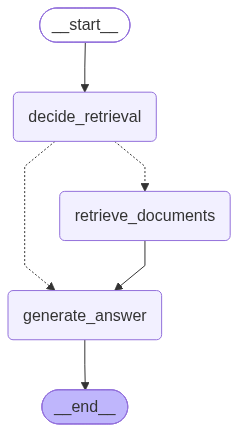

In [109]:
app

In [110]:
# for name, value in list(globals().items()):
#     try:
#         if (
#             isinstance(value, list)
#             and len(value) > 0
#             and hasattr(value[0], "page_content")
#             and hasattr(value[0], "metadata")
#         ):
#             print(f"{name} -> {len(value)} documents")

#         elif hasattr(value, "docstore") and hasattr(value, "index"):
#             print(f"{name} -> Possible FAISS vector store")

#     except Exception:
#         pass

In [111]:
# response = llm.invoke(
#     "Reply with exactly: LLM is working."
# )

# print("LLM response:", repr(response.content))

In [ ]:
result = app.invoke({
    "question": "What do customers say about its cooling performance and noise level?",
    "context": [],
    "answer": "",
    "needs_retrieval": True,
})



print("Answer:\n", result["answer"])

Generating answer with LLM...
LLM response: AIMessage(content='**Cooling Performance**\n\n| Product | Positive Notes | Negative Notes |\n|---------|----------------|----------------|\n| Crompton 75\u202fL | “speed and cooling are awesome,” “best cooling experience,” “cooling capacity is very good,” “cooling is awesome,” “cooling is decent” | “cooling wise its good but noisy,” “not cooling within 15 mins,” “needs proper ventilation,” “fan doesn’t move fast” |\n| MAHARAJA WHITELINE 65\u202fL | “best cooler,” “cooling is superb,” “cooling air awesome,” “cooler performance is excellent,” “very nice cooler” | “does not cool within 15 mins,” “fan speed low and does not proper cooling,” “little noise” |\n\n**Noise Level**\n\n| Product | Positive Notes | Negative Notes |\n|---------|----------------|----------------|\n| Crompton 75\u202fL | “less noise,” “little noisy but cooling is awesome,” “noisy but cools the room” | “noisy gives you AC feeling,” “water dropping noise will irritate you,” “